# Robust Regression V3

This notebook starts from one-dimensional mechanisms and then checks whether they persist at `p=2` and `p=5`.

## Reading order

Run the final code cell. It executes Benchmarks A–D in this order: one-dimensional explanation first, multivariate extension second.

## Shared design

All experiments use clean held-out test data. Training data alone receives contamination. The same synthetic coefficient pattern begins with `y = 2x1 + noise` when `p=1`.

## Benchmark A — contamination layouts

Compare one-sided response shifts, random symmetric shifts, and left-up/right-down shifts coupled to `x1`.

## Benchmark B — robust recovery

First compare OLS and robust regression in a visible one-dimensional example; then compare per-parameter errors at `p=2` and `p=5`.

## Benchmark C — failure boundary

Start from a one-dimensional distance curve, then use a ratio-by-distance matrix for the multivariate extension.

## Benchmark D — two legitimate structures

Start from two true one-dimensional lines, then compare single regression, robust regression, and an oracle two-regression reference.


## Output contract

Figures display directly in the final cell and PNG copies are written to `release/output/`. The final cell is self-contained and can be run independently.

V3 figures are displayed below; PNG copies are in release/output.\n

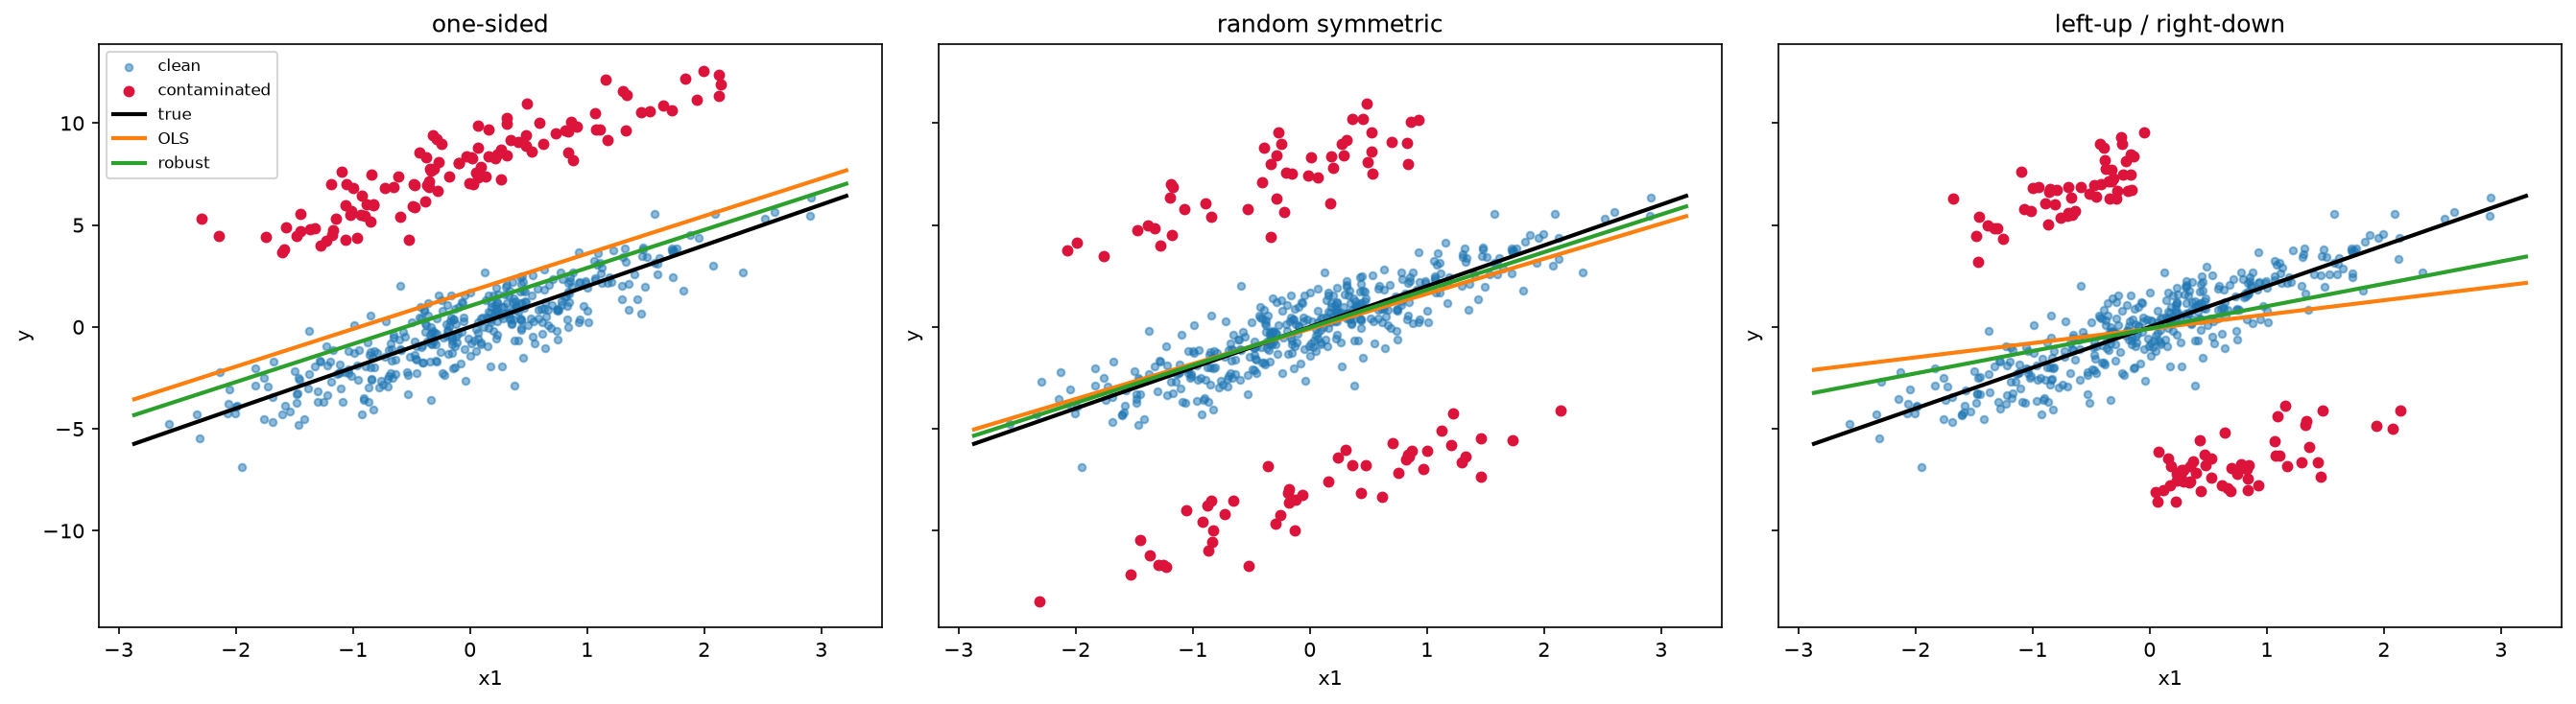

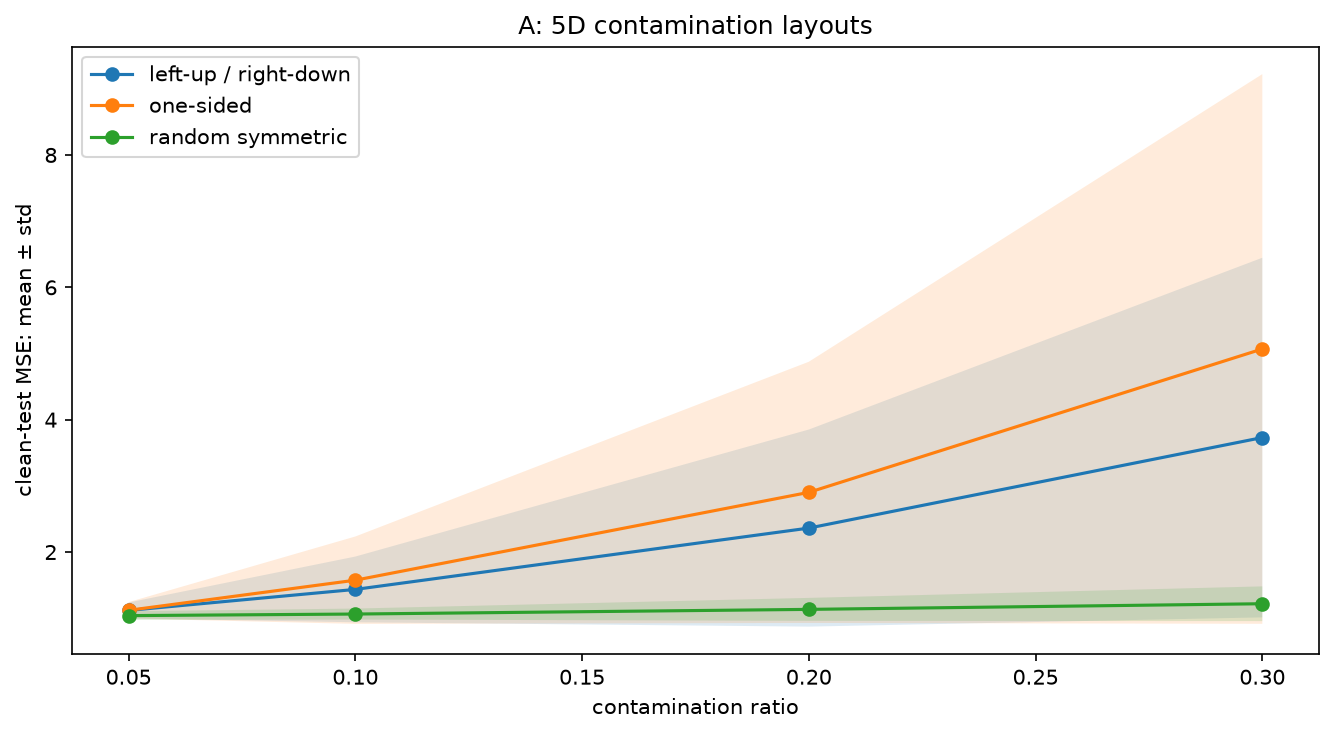

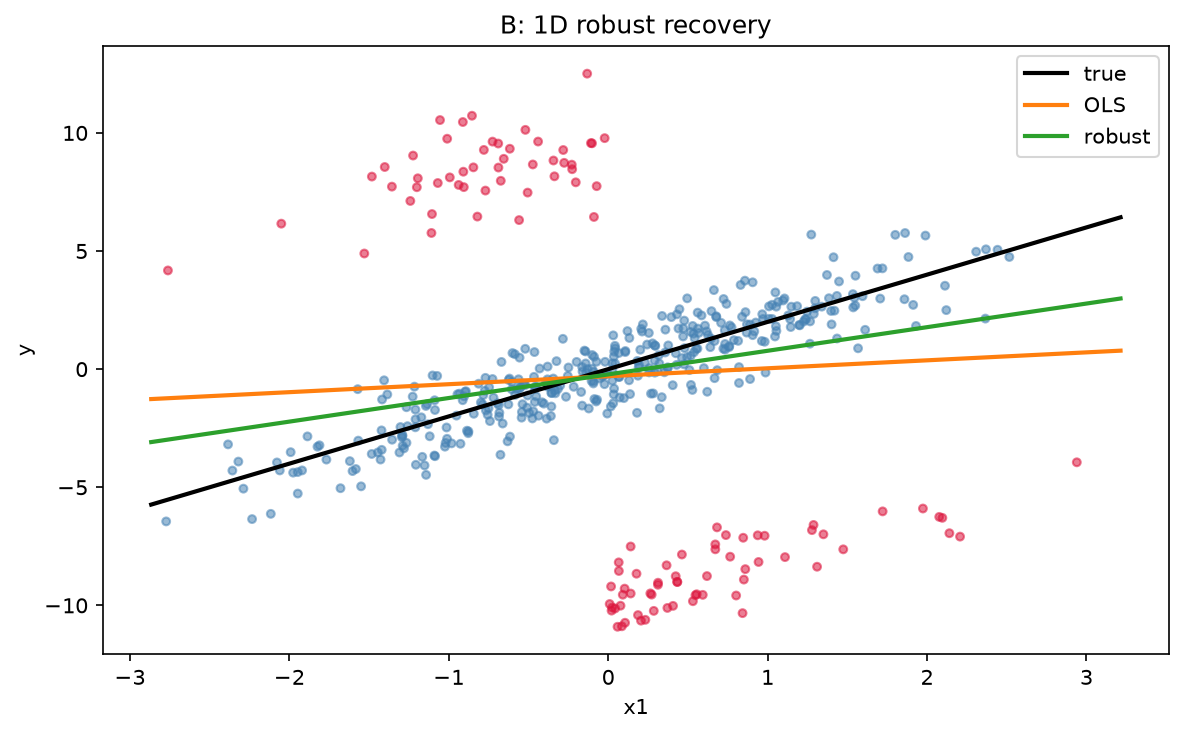

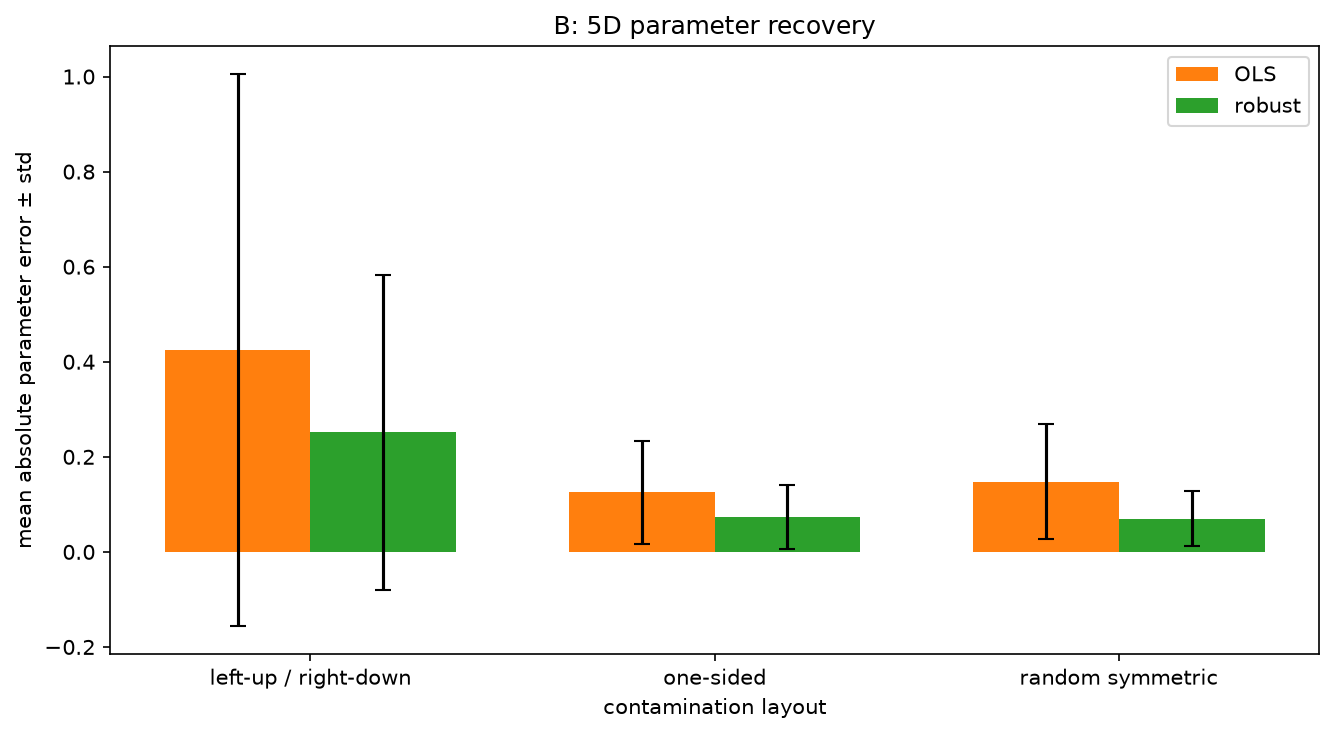

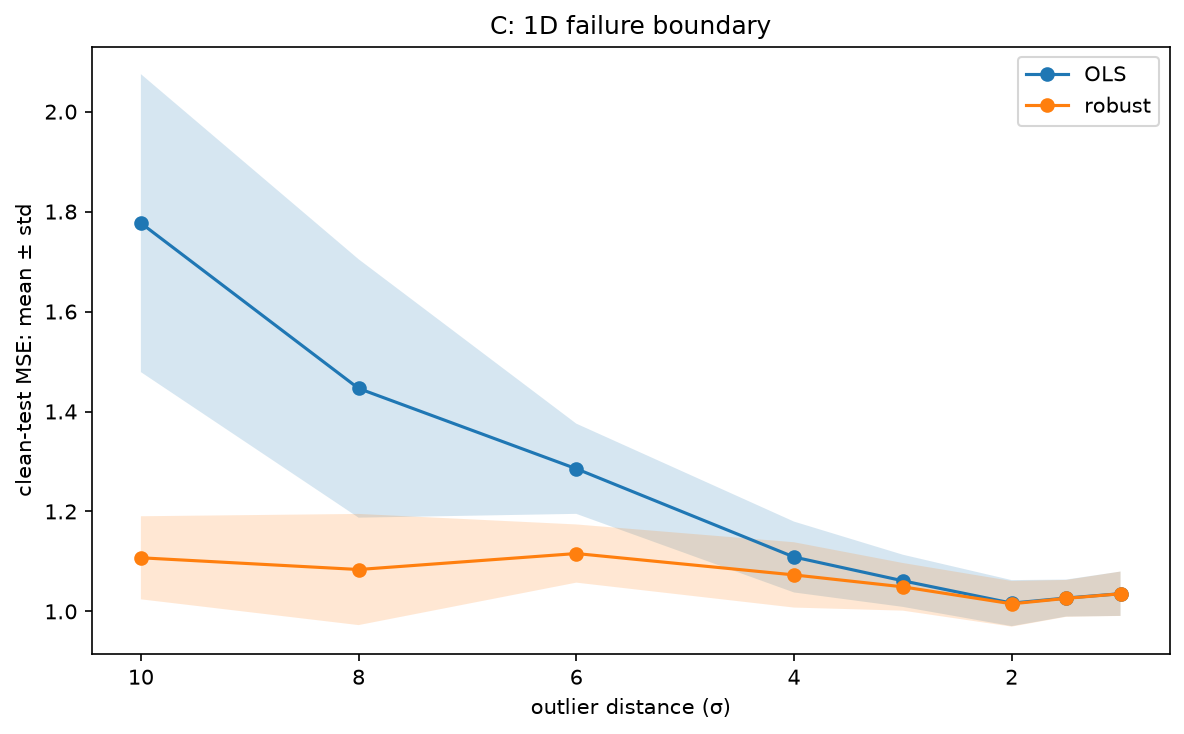

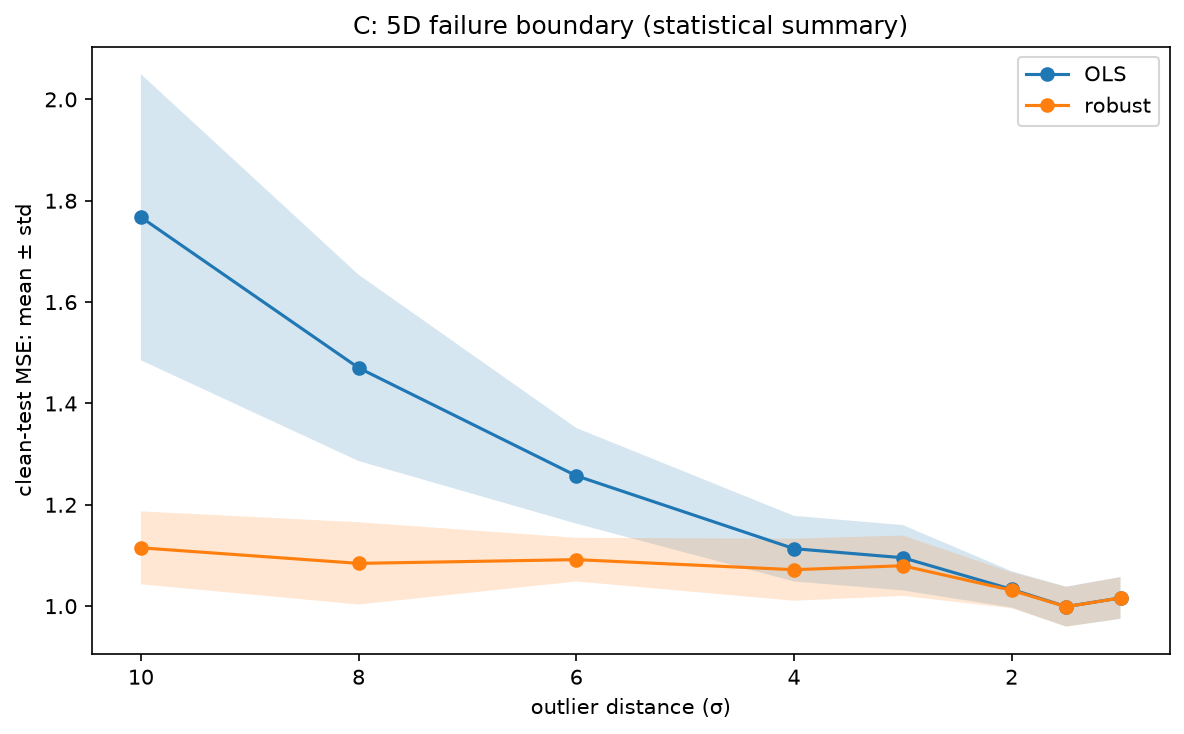

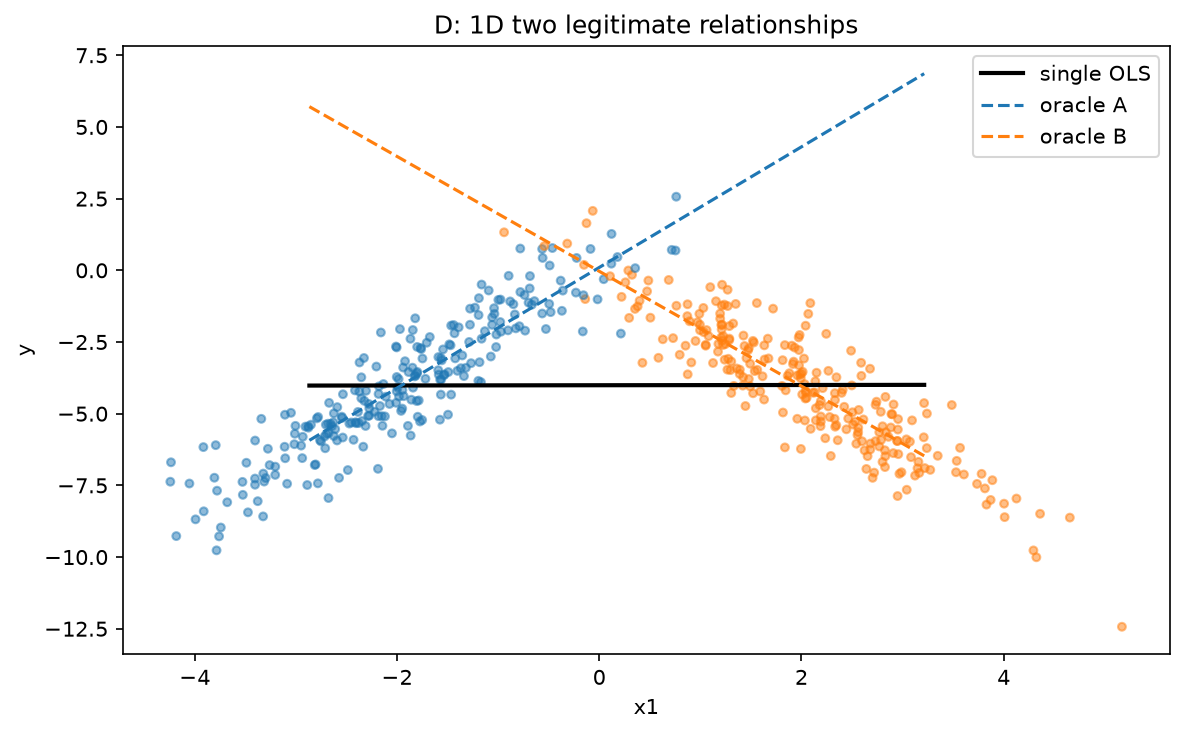

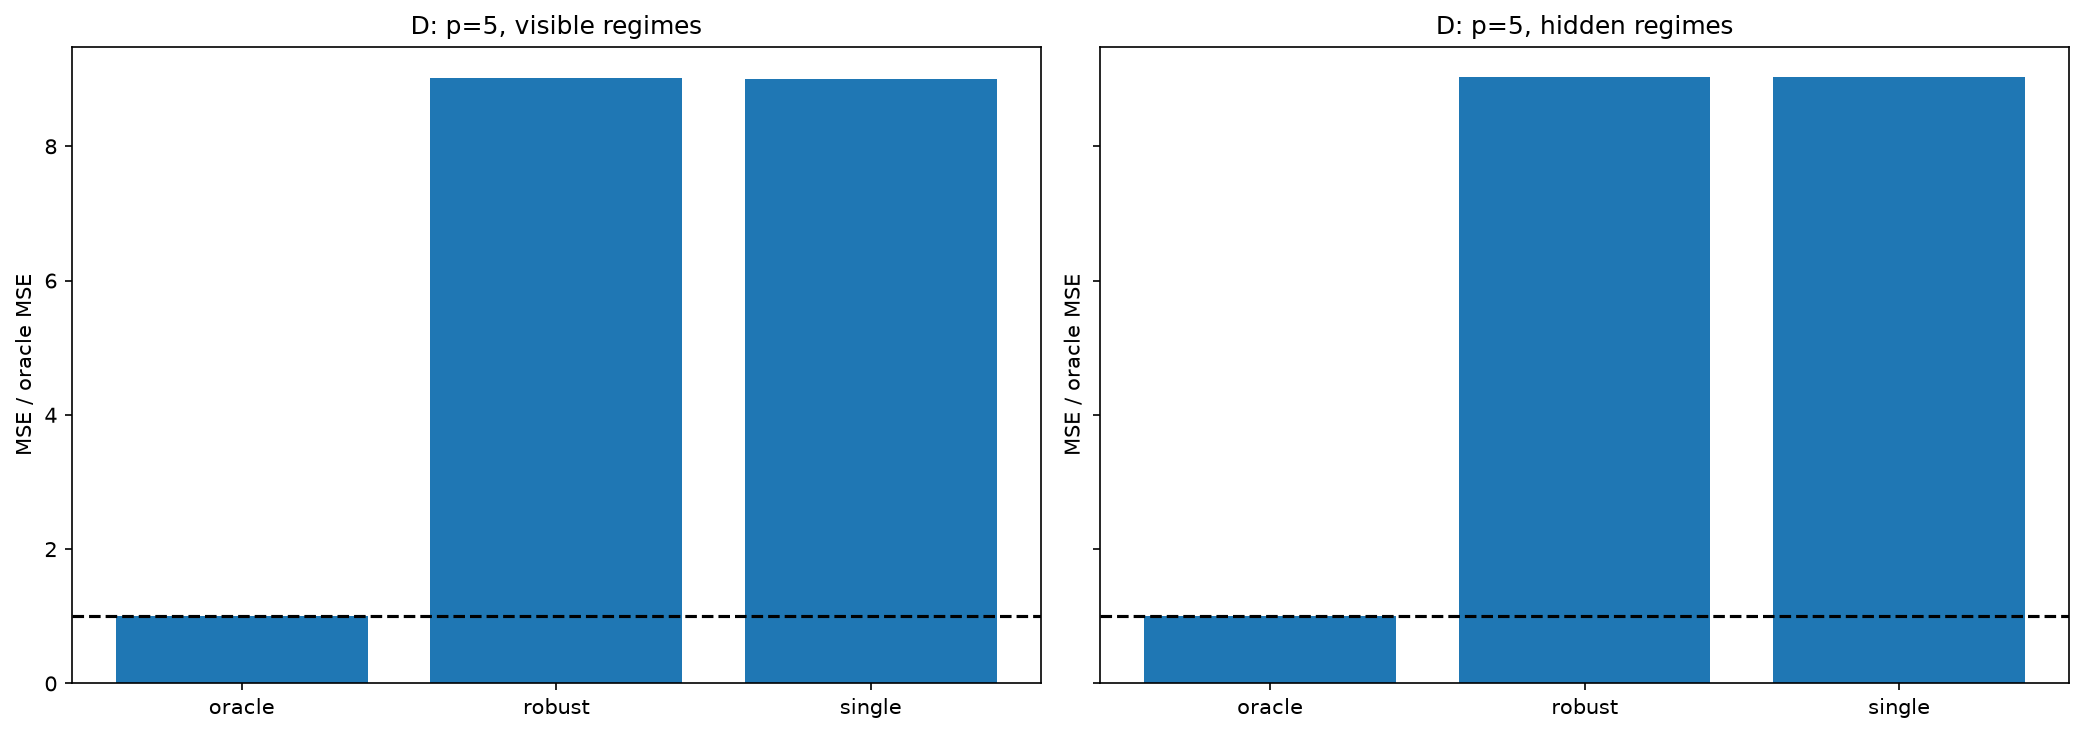

In [9]:
# V3 execution cell — one-dimensional mechanism first, then p=2 and p=5 extensions
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from pathlib import Path

OUT=Path("release/output"); OUT.mkdir(parents=True,exist_ok=True)
RNG_SEED=42; N=500; NT=1000; SIGMA=1.; REPS=12; PS=[1,2,5]
layouts=["one-sided","random symmetric","left-up / right-down"]

def beta(p): return np.array([2.,-1.5,1.,-.75,.5])[:p]
def data(p,seed):
    g=np.random.default_rng(seed); b=beta(p); X=g.normal(size=(N,p)); y=X@b+g.normal(size=N); Xt=g.normal(size=(NT,p)); yt=Xt@b+g.normal(size=NT); return b,X,y,Xt,yt,g
def contam(X,y,kind,ratio,mag,g):
    m=g.random(len(y))<ratio; sign=np.ones(len(y))
    if kind=="random symmetric": sign=g.choice([-1.,1.],len(y))
    if kind=="left-up / right-down": sign=-np.sign(X[:,0]); sign[sign==0]=1
    z=y.copy(); z[m]+=sign[m]*mag; return z,m
def D(X): return np.c_[np.ones(len(X)),X]
def fit(X,y): return np.linalg.lstsq(D(X),y,rcond=None)[0]
def rfit(X,y):
    A=D(X); t=fit(X,y)
    for _ in range(40):
        r=y-A@t; scale=max(1.4826*np.median(abs(r-np.median(r))),1e-12); w=np.minimum(1,2.5*scale/np.maximum(abs(r),1e-12)); u=np.linalg.lstsq(A*np.sqrt(w)[:,None],y*np.sqrt(w),rcond=None)[0]
        if np.linalg.norm(u-t)<1e-8*(1+np.linalg.norm(t)): return u
        t=u
    return t
def score(X,y,t,b): return np.mean((y-D(X)@t)**2),np.linalg.norm(t[1:]-b)
def save(fig,name): fig.tight_layout(); fig.savefig(OUT/name,dpi=180,bbox_inches="tight"); plt.show()
def hm(ax,m,title):
    im=ax.imshow(m.values,aspect="auto",cmap="magma"); ax.set(title=title,xlabel="magnitude σ",ylabel="condition"); ax.set_xticks(range(len(m.columns)),m.columns); ax.set_yticks(range(len(m.index)),m.index)
    for i in range(m.shape[0]):
        for j in range(m.shape[1]): ax.text(j,i,f"{m.iloc[i,j]:.2f}",ha="center",va="center",fontsize=7,color="white" if m.iloc[i,j]>m.values.mean() else "black")
    plt.colorbar(im,ax=ax,shrink=.8)

# A — 1D mechanisms; then test the same mechanisms at p=2 and p=5.
b,X,y,Xt,yt,g=data(1,RNG_SEED); xx=np.linspace(X[:,0].min()-.3,X[:,0].max()+.3,200); fig,axs=plt.subplots(1,3,figsize=(18,5),sharey=True)
for ax,k in zip(axs,layouts):
    z,m=contam(X,y,k,.2,8,g); o=fit(X,z); r=rfit(X,z); ax.scatter(X[~m,0],z[~m],s=13,alpha=.5,label="clean"); ax.scatter(X[m,0],z[m],s=22,c="crimson",label="contaminated"); ax.plot(xx,b[0]*xx,c="black",lw=2,label="true"); ax.plot(xx,o[0]+o[1]*xx,c="tab:orange",lw=2,label="OLS"); ax.plot(xx,r[0]+r[1]*xx,c="tab:green",lw=2,label="robust"); ax.set(title=k,xlabel="x1",ylabel="y")
axs[0].legend(fontsize=8); save(fig,"v3_a_1d_mechanisms.png")
rows=[]
for p0 in PS:
 for k in layouts:
  for q in [.05,.1,.2,.3]:
   for mag in [2.,5.,10.]:
    for rep in range(REPS):
     b,X,y,Xt,yt,g=data(p0,RNG_SEED+100000*p0+10000*rep+int(q*100)+int(mag)); z,_=contam(X,y,k,q,mag,g); mse,pe=score(Xt,yt,fit(X,z),b); rows.append([p0,k,q,mag,rep,mse,pe])
a=pd.DataFrame(rows,columns=["p","layout","ratio","magnitude","seed","MSE","parameter_error"]); display(a.groupby(["p","layout","ratio","magnitude"],as_index=False)[["MSE","parameter_error"]].mean())
fig,axs=plt.subplots(1,2,figsize=(14,5))
for ax,p0,metric in [(axs[0],1,"MSE"),(axs[1],5,"parameter_error")]:
 d=a[(a.p==p0)&(a.layout=="left-up / right-down")].groupby(["ratio","magnitude"],as_index=False)[metric].mean(); hm(ax,d.pivot(index="ratio",columns="magnitude",values=metric),f"A: diagonal layout, p={p0}, {metric}")
# A: p=5 statistical extension — no point cloud or fitted line.
a_stats=a.groupby(["p","layout","ratio"],as_index=False).MSE.agg(mean="mean",std="std")
fig,ax=plt.subplots(figsize=(9,5))
for layout,x in a_stats[a_stats.p==5].groupby("layout"):
    x=x.sort_values("ratio"); ax.plot(x.ratio,x["mean"],marker="o",label=layout); ax.fill_between(x.ratio,x["mean"]-x["std"],x["mean"]+x["std"],alpha=.15)
ax.set(title="A: 5D contamination layouts",xlabel="contamination ratio",ylabel="clean-test MSE: mean ± std"); ax.legend()
save(fig,"v3_a_5d_statistics.png")

# B — same 1D diagonal example; then compare coefficient recovery in p=5.
b,X,y,Xt,yt,g=data(1,RNG_SEED+1); z,m=contam(X,y,"left-up / right-down",.2,10,g); o,r=fit(X,z),rfit(X,z); fig,ax=plt.subplots(figsize=(8,5)); ax.scatter(X[:,0],z,s=14,c=np.where(m,"crimson","steelblue"),alpha=.55); ax.plot(xx,b[0]*xx,c="black",lw=2,label="true"); ax.plot(xx,o[0]+o[1]*xx,c="tab:orange",lw=2,label="OLS"); ax.plot(xx,r[0]+r[1]*xx,c="tab:green",lw=2,label="robust"); ax.set(title="B: 1D robust recovery",xlabel="x1",ylabel="y"); ax.legend(); save(fig,"v3_b_1d_robust.png")
rr=[]
for p0 in PS:
 for k in layouts:
  for rep in range(REPS):
   b,X,y,Xt,yt,g=data(p0,RNG_SEED+200000*p0+1000*rep); z,_=contam(X,y,k,.2,10,g)
   for method,t in [("OLS",fit(X,z)),("robust",rfit(X,z))]:
    for j in range(p0): rr.append([p0,k,rep,method,f"x{j+1}",abs(t[j+1]-b[j])])
btab=pd.DataFrame(rr,columns=["p","layout","seed","method","feature","abs_parameter_error"]); display(btab.groupby(["p","layout","method"],as_index=False).abs_parameter_error.mean())
fig,axs=plt.subplots(1,2,figsize=(14,5),sharey=True)
for ax,method in zip(axs,["OLS","robust"]): hm(ax,btab[(btab.p==5)&(btab.method==method)].groupby(["layout","feature"],as_index=False).abs_parameter_error.mean().pivot(index="layout",columns="feature",values="abs_parameter_error"),f"B: p=5 parameter error, {method}")
# B: p=5 statistical extension — OLS versus robust parameter recovery.
b_stats=btab[btab.p==5].groupby(["layout","method"],as_index=False).abs_parameter_error.agg(mean="mean",std="std")
fig,ax=plt.subplots(figsize=(9,5)); order=list(b_stats.layout.drop_duplicates()); pos=np.arange(len(order)); width=.36
for offset,method,color in [(-width/2,"OLS","tab:orange"),(width/2,"robust","tab:green")]:
    x=b_stats[b_stats.method==method].set_index("layout").reindex(order); ax.bar(pos+offset,x["mean"],width,yerr=x["std"],capsize=4,label=method,color=color)
ax.set(title="B: 5D parameter recovery",xlabel="contamination layout",ylabel="mean absolute parameter error ± std",xticks=pos,xticklabels=order); ax.legend()
save(fig,"v3_b_5d_parameter_statistics.png")

# C — one-dimensional failure line; then p=5 ratio × distance robust-gain matrix.
cr=[]
for p0 in PS:
 for q in [.05,.1,.2,.3]:
  for dist in [10.,8.,6.,4.,3.,2.,1.5,1.]:
   for rep in range(REPS):
    b,X,y,Xt,yt,g=data(p0,RNG_SEED+300000*p0+10000*int(q*100)+100*int(dist*10)+rep); z,_=contam(X,y,"left-up / right-down",q,dist,g)
    for method,t in [("OLS",fit(X,z)),("robust",rfit(X,z))]: cr.append([p0,q,dist,rep,method,score(Xt,yt,t,b)[0]])
c=pd.DataFrame(cr,columns=["p","ratio","distance","seed","method","MSE"]); cs=c.groupby(["p","ratio","distance","method"],as_index=False).MSE.mean(); display(cs)
c_stats=c.groupby(["p","ratio","distance","method"],as_index=False).MSE.agg(mean="mean",std="std")
for p_plot, filename, title in [
    (1, "v3_c_1d_failure_boundary.png", "C: 1D failure boundary"),
    (5, "v3_c_5d_failure_boundary.png", "C: 5D failure boundary (statistical summary)"),
]:
    fig,ax=plt.subplots(figsize=(8,5)); d=c_stats[(c_stats.p==p_plot)&(c_stats.ratio==.1)]
    for method,x in d.groupby("method"):
        x=x.sort_values("distance")
        ax.plot(x.distance,x["mean"],marker="o",label=method)
        ax.fill_between(x.distance,x["mean"]-x["std"],x["mean"]+x["std"],alpha=.18)
    ax.set(title=title,xlabel="outlier distance (σ)",ylabel="clean-test MSE: mean ± std")
    ax.invert_xaxis(); ax.legend()
    save(fig,filename)

# D — two legitimate 1D lines, then compare against an oracle; oracle is the explicit performance reference.
def regimes(n,p0,visible,g):
 lab=g.random(n)<.5; X=g.normal(size=(n,p0)); X[:,0]+=np.where(lab,2.,-2.) if visible else 0; B=np.where(lab[:,None],-beta(p0),beta(p0)); return X,np.einsum("ij,ij->i",X,B)+g.normal(size=n),lab
g=np.random.default_rng(RNG_SEED+9); X,y,lab=regimes(N,1,True,g); one=fit(X,y); ta,tb=fit(X[~lab],y[~lab]),fit(X[lab],y[lab]); fig,ax=plt.subplots(figsize=(8,5)); ax.scatter(X[:,0],y,c=np.where(lab,"tab:orange","tab:blue"),s=14,alpha=.5); ax.plot(xx,one[0]+one[1]*xx,c="black",lw=2,label="single OLS"); ax.plot(xx,ta[0]+ta[1]*xx,"--",label="oracle A"); ax.plot(xx,tb[0]+tb[1]*xx,"--",label="oracle B"); ax.set(title="D: 1D two legitimate relationships",xlabel="x1",ylabel="y"); ax.legend(); save(fig,"v3_d_1d_two_relations.png")
dr=[]
for p0 in PS:
 for visible in [True,False]:
  for rep in range(REPS):
   g=np.random.default_rng(RNG_SEED+400000*p0+10000*visible+rep); X,y,lab=regimes(N,p0,visible,g); Xt,yt,lt=regimes(NT,p0,visible,g); oa,ob=fit(X[~lab],y[~lab]),fit(X[lab],y[lab]); pred={"single":D(Xt)@fit(X,y),"robust":D(Xt)@rfit(X,y),"oracle":np.where(lt,D(Xt)@ob,D(Xt)@oa)}; om=np.mean((yt-pred["oracle"])**2)
   for method,v in pred.items(): dr.append([p0,"visible" if visible else "hidden",rep,method,np.mean((yt-v)**2)/om])
dd=pd.DataFrame(dr,columns=["p","case","seed","method","MSE_over_oracle"]); ds=dd.groupby(["p","case","method"],as_index=False).MSE_over_oracle.mean(); display(ds)
fig,axs=plt.subplots(1,2,figsize=(14,5),sharey=True)
for ax,case in zip(axs,["visible","hidden"]):
 d=ds[(ds.p==5)&(ds.case==case)]; ax.bar(d.method,d.MSE_over_oracle); ax.axhline(1,c="black",ls="--"); ax.set(title=f"D: p=5, {case} regimes",ylabel="MSE / oracle MSE")
save(fig,"v3_d_multidimensional_controls.png")
print("V3 complete: every benchmark printed a 1D mechanism figure and a multivariate extension; PNG copies are in release/output.")
